# Assignment 5, Problem 1: Residual-based refinement of a Gaussian solution (60 marks)

The purpose is to check **where the estimator places refinement** and how much refinement is needed to reach a specified true error. The exact solution is known only for this verification problem; do not use it to select elements in the adaptive loop.

Save this notebook as `lastname_assignment05_gaussian.ipynb`. Use **Python (Finite Elements)** on one MPI process. The supplied cells solve the initial problem and carry out one refinement. Complete the three tasks after those cells. Submit this notebook with your code, figures, tables, and short answers.

Use the given $P_1$ space, initial mesh, source, and degree-20 volume quadrature throughout. The solver, residual assembly, marking, refinement, and plotting functions are supplied. You will write the repeated adaptive loop, not a new PDE solver.


## Supplied problem and first refinement

The localized exact solution below is adapted from Larson and Bengzon, *The Finite Element Method: Theory, Implementation, and Practice* (2010 notes), §4.9.3, Eq. (4.130). Its boundary correction makes the prescribed values exactly zero.

Run the cells in order. They expose one solve–estimate–mark–refine step. Complete the assignment tasks only after checking this supplied calculation.


## Setup and plotting
Run these cells first. The macOS compiler selection is explained in [environment/README.md](../../../environment/README.md).


In [1]:
import os
import sys
from pathlib import Path

if sys.platform == "darwin" and Path("/usr/bin/clang").exists():
    os.environ.setdefault("CC", "/usr/bin/clang")
    os.environ.setdefault("LDSHARED", "/usr/bin/clang -bundle -undefined dynamic_lookup")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import ufl
import dolfinx
from mpi4py import MPI
from petsc4py import PETSc
from dolfinx import fem, mesh, plot
from dolfinx.fem.petsc import LinearProblem

plt.rcParams.update({"font.size": 16, "axes.titlesize": 17})
print("DOLFINx:", dolfinx.__version__)


DOLFINx: 0.11.0


In [2]:
def mesh_triangles(domain):
    cells, _, coordinates = plot.vtk_mesh(domain)
    return mtri.Triangulation(
        coordinates[:, 0], coordinates[:, 1], cells.reshape(-1, 4)[:, 1:]
    )

def draw_mesh(ax, domain, title, marked=None, zoom=None):
    triangles = mesh_triangles(domain)
    if marked is not None:
        colors = np.zeros(len(triangles.triangles))
        colors[marked] = 1
        ax.tripcolor(triangles, facecolors=colors, cmap="Blues", vmin=0, vmax=1.8)
    ax.triplot(triangles, color="0.25", linewidth=0.35)
    ax.set(title=title, xlabel=r"$x_1$", ylabel=r"$x_2$")
    ax.set_aspect("equal")
    if zoom is not None:
        ax.set_xlim(-zoom, zoom)
        ax.set_ylim(-zoom, zoom)

def show_state(domain, V, u_h, eta_squared):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.1), layout="constrained")
    fig.get_layout_engine().set(wspace=0.12)
    draw_mesh(axes[0], domain, "Current mesh")
    cells, _, coordinates = plot.vtk_mesh(V)
    triangles = mtri.Triangulation(
        coordinates[:, 0], coordinates[:, 1], cells.reshape(-1, 4)[:, 1:]
    )
    solution = axes[1].tripcolor(triangles, u_h.x.array.real, shading="gouraud")
    axes[1].set(title=r"FE solution $u_h$", xlabel=r"$x_1$", ylabel=r"$x_2$")
    axes[1].set_aspect("equal")
    fig.colorbar(solution, ax=axes[1], shrink=0.8)
    indicators = axes[2].tripcolor(
        mesh_triangles(domain), facecolors=np.sqrt(eta_squared), cmap="magma",
        edgecolors="0.35", linewidth=0.2,
    )
    axes[2].set(title=r"Element indicators $\eta_e$", xlabel=r"$x_1$", ylabel=r"$x_2$")
    axes[2].set_aspect("equal")
    fig.colorbar(indicators, ax=axes[2], shrink=0.8)
    return fig

def show_refinement(old_domain, new_domain, marked):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
    draw_mesh(axes[0], old_domain, "Marked elements (blue)", marked)
    draw_mesh(axes[1], new_domain, "Mesh after refinement")
    return fig


## 1. A localized solution on the unit square
Let $\Omega=(0,1)^2$ and solve
$$
-\Delta u=f\quad\text{in }\Omega,\qquad u=0\quad\text{on }\partial\Omega.
$$
Use $\alpha=400$, $s_i=x_i-\tfrac12$, $G_i=\exp(-\alpha s_i^2)$, and $c=\exp(-\alpha/4)$. Choose
$$
u_{\rm ex}(x_1,x_2)=(G_1-c)(G_2-c),
$$
$$
f(x_1,x_2)=-\Delta u_{\rm ex}
=2\alpha\left[(1-2\alpha s_1^2)G_1(G_2-c)
 +(1-2\alpha s_2^2)G_2(G_1-c)\right].
$$
On each boundary edge, one factor $G_i-c$ is zero, so the exact solution satisfies the prescribed values.

The factors $G_i-c$ make Larson's Gaussian pulse exactly zero on the boundary. UFL differentiates the expression for $u_{\rm ex}$ to obtain $f$.

The narrow Gaussian pulse needs enough integration points even on a coarse mesh. We use degree-20 quadrature for the volume integrals. This sets the integration rule, not the polynomial degree of the $P_1$ finite elements.


In [3]:
quadrature_degree = 20

def create_square_mesh():
    domain = mesh.create_unit_square(MPI.COMM_SELF, 8, 8)
    domain.topology.create_entities(1)
    return domain

def pulse_data(domain):
    x = ufl.SpatialCoordinate(domain)
    alpha = 400.0
    c = np.exp(-alpha / 4.0)
    G1 = ufl.exp(-alpha * (x[0] - 0.5)**2)
    G2 = ufl.exp(-alpha * (x[1] - 0.5)**2)
    u_exact = (G1 - c) * (G2 - c)
    f = -ufl.div(ufl.grad(u_exact))
    return u_exact, f

domain = create_square_mesh()
u_exact, f = pulse_data(domain)


## 2. Solve on the initial mesh
Use continuous piecewise-linear functions:
$$
\mathcal V_{h,0}
=\{v_h\in H^1_0(\Omega):v_h|_{\mathcal K_e}\in P_1(\mathcal K_e)\}.
$$
Define the bilinear and linear forms
$$
a(w,v)=\int_\Omega\nabla w\cdot\nabla v\,dx,
\qquad \ell(v)=\int_\Omega fv\,dx.
$$
Find $u_h\in\mathcal V_{h,0}$ such that
$$
a(u_h,v_h)=\ell(v_h)\quad\forall v_h\in\mathcal V_{h,0}.
$$
In two dimensions, FEniCSx identifies edges by dimension 1 and elements by dimension 2. `create_connectivity(1, 2)` records which elements touch each edge. We then find the exterior edges and prescribe zero at their degrees of freedom.

`LinearProblem` assembles and solves the variational problem. Its LU options select a direct linear solver. The scalar space `V` includes boundary degrees of freedom, whose values are prescribed by `bc`.

FEniCSx uses `cell` in its API and zero-based array indices; these are elements in our mathematical notation.


In [4]:
def solve_diffusion(domain, f):
    domain.topology.create_connectivity(1, 2)
    V = fem.functionspace(domain, ("Lagrange", 1))
    trial = ufl.TrialFunction(V)
    test = ufl.TestFunction(V)

    boundary_facets = mesh.exterior_facet_indices(domain.topology)
    boundary_dofs = fem.locate_dofs_topological(V, 1, boundary_facets)
    bc = fem.dirichletbc(PETSc.ScalarType(0.0), boundary_dofs, V)

    a = ufl.inner(ufl.grad(trial), ufl.grad(test)) * ufl.dx
    dx = ufl.Measure("dx", domain=domain,
                     metadata={"quadrature_degree": quadrature_degree})
    L = f * test * dx
    problem = LinearProblem(
        a, L, bcs=[bc], petsc_options_prefix="residual_diffusion_",
        petsc_options={"ksp_type": "preonly", "pc_type": "lu"},
    )
    u_h = problem.solve()
    return V, u_h

V, u_h = solve_diffusion(domain, f)
print("Elements:", domain.topology.index_map(2).size_local)
print("Total scalar FE degrees of freedom:", V.dofmap.index_map.size_global)


Elements: 128
Total scalar FE degrees of freedom: 81


## 3. Compute the residual indicators
Since $u_h$ is linear on each triangle and $k=1$,
$$
r_e=f+\Delta u_h=f,\qquad
j_{\mathcal F}
=-\left(\nabla u_h^+\cdot\mathbf n^+
       +\nabla u_h^-\cdot\mathbf n^-\right).
$$
The normals point outward from the two neighboring elements. UFL's `jump(grad(u_h), normal)` computes their sum.

The local and global estimators are exactly those used in the lecture:
$$
\eta_e^2=h_e^2\int_{\mathcal K_e}r_e^2\,dx
+\frac12\sum_{\substack{\mathcal F\subset\partial\mathcal K_e\\
                       \mathcal F\ {\rm interior}}}
h_{\mathcal F}\int_{\mathcal F}j_{\mathcal F}^2\,ds.
$$
Sum the squared indicators to obtain the global estimator:
$$
\eta=\left(\sum_e\eta_e^2\right)^{1/2}.
$$
Here $h_e$ is element diameter and $h_{\mathcal F}$ is edge length. There is no Neumann term because all boundary values are prescribed.

### One assembled entry per element
The discontinuous constant space `DG0` has one basis function $z_e$ per element, equal to 1 there and 0 elsewhere.

The PDE solution still uses continuous $P_1$ elements. DG0 is used only to assemble the element indicators; this does not make the PDE discretization a discontinuous Galerkin method. Although $u_h$ is continuous, its gradient can jump between elements, which is why the facet term appears in the estimator.

- Integrating $h^2r^2z_e$ gives that element's volume contribution.
- On an interior edge, $z_e^+$ and $z_e^-$ are the test-function values from the two neighboring elements. The two half contributions in the code are exactly $h_{\mathcal F}j_{\mathcal F}^2(z_e^++z_e^-)/2$.
- `dS` integrates over interior edges. In 2D, `avg(FacetArea(domain))` is their length.

The assembled entries are already squared indicators: do **not** divide by element area.

`fem.form` prepares an integral for numerical assembly; `assemble_vector` evaluates it against every DG0 test basis function. DG0 degree-of-freedom numbers need not be the geometric element numbers. The final loop retrieves the one DG0 entry belonging to each element, so the arrays used for marking follow element order.


Element contribution to eta^2: 157.079509


Facet contribution to eta^2:   7.886346
Global estimator eta:          12.843903


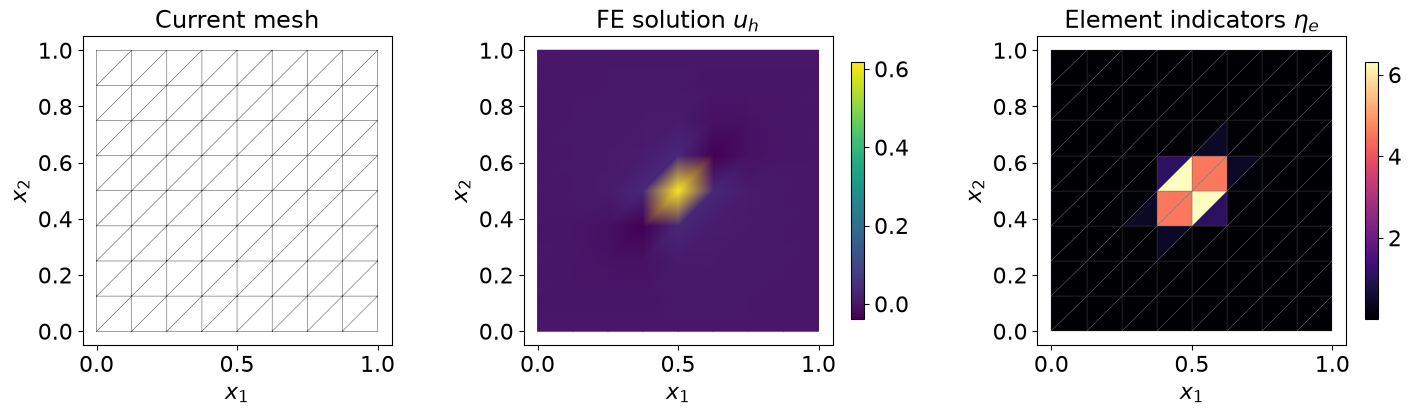

In [5]:
def estimate_error(domain, u_h, f):
    W = fem.functionspace(domain, ("DG", 0))
    z = ufl.TestFunction(W)
    h = ufl.CellDiameter(domain)
    h_F = ufl.avg(ufl.FacetArea(domain))
    normal = ufl.FacetNormal(domain)
    r = f + ufl.div(ufl.grad(u_h))
    j = -ufl.jump(ufl.grad(u_h), normal)

    dx = ufl.Measure("dx", domain=domain,
                     metadata={"quadrature_degree": quadrature_degree})
    element_form = h**2 * r**2 * z * dx
    facet_form = (
        0.5 * h_F * j**2 * z("+") * ufl.dS
        + 0.5 * h_F * j**2 * z("-") * ufl.dS
    )
    element_vector = fem.assemble_vector(fem.form(element_form))
    facet_vector = fem.assemble_vector(fem.form(facet_form))

    count = domain.topology.index_map(2).size_local
    element_part = np.zeros(count)
    facet_part = np.zeros(count)
    for e in range(count):
        dof = W.dofmap.cell_dofs(e)[0]
        element_part[e] = element_vector.array[dof].real
        facet_part[e] = facet_vector.array[dof].real
    return element_part, facet_part

element_part, facet_part = estimate_error(domain, u_h, f)
eta_squared = element_part + facet_part
eta = np.sqrt(np.sum(eta_squared))

print(f"Element contribution to eta^2: {np.sum(element_part):.6f}")
print(f"Facet contribution to eta^2:   {np.sum(facet_part):.6f}")
print(f"Global estimator eta:          {eta:.6f}")
show_state(domain, V, u_h, eta_squared)
plt.show()


## 4. Compare the estimator with the known error
For this verification problem the exact energy error can be integrated:
$$
E_a=\|u_{\rm ex}-u_h\|_a
=\left(\int_\Omega\nabla(u_{\rm ex}-u_h)\cdot
                 \nabla(u_{\rm ex}-u_h)\,dx\right)^{1/2}.
$$
Compare it with the estimator using the effectivity:
$$
I_{\rm eff}=\frac{\eta}{E_a}.
$$
This error calculation uses the analytic $u_{\rm ex}$, not its nodal interpolant. It is only a check on the estimator; marking below does not use the exact solution.


In [6]:
def energy_error(domain, u_h, u_exact):
    error = u_exact - u_h
    dx = ufl.Measure("dx", domain=domain,
                     metadata={"quadrature_degree": quadrature_degree})
    squared_error = fem.assemble_scalar(fem.form(
        ufl.inner(ufl.grad(error), ufl.grad(error)) * dx
    ))
    return np.sqrt(squared_error)

error = energy_error(domain, u_h, u_exact)
print(f"Energy error: {error:.6f}")
print(f"Estimator:    {eta:.6f}")
print(f"Effectivity:  {eta / error:.3f}")


Energy error: 1.323294
Estimator:    12.843903
Effectivity:  9.706


## 5. Mark elements using the indicators

Dörfler marking selects a set $\mathcal M$ such that
$$
\sum_{\mathcal K_e\in\mathcal M}\eta_e^2
\ge\theta\sum_e\eta_e^2.
$$
Choose $\theta=0.5$: the marked elements must account for at least half of the squared estimator. `argsort` supplies element indices in increasing indicator order; reversing that order puts the largest first. The loop adds elements until their squared indicators reach the target.

The selected elements are identified from the computed residuals; no knowledge of the exact error is used. The table below lists the six largest squared indicators, separated into volume and facet contributions. Compare its first rows with the printed marked-element IDs. IDs in this table are Python's zero-based element indices.


In [7]:
def mark_elements(eta_squared, theta):
    order = np.argsort(eta_squared)[::-1]
    target = theta * np.sum(eta_squared)
    selected_sum = 0.0
    marked = []
    for e in order:
        marked.append(e)
        selected_sum += eta_squared[e]
        if selected_sum >= target:
            break
    return np.array(marked, dtype=np.int32)

theta = 0.5
marked = mark_elements(eta_squared, theta)
fraction = np.sum(eta_squared[marked]) / np.sum(eta_squared)
print(f"Marked {len(marked)} of {len(eta_squared)} elements")
print(f"Fraction of eta^2 selected: {fraction:.3f}")
print("Marked element IDs:", marked)

largest = np.argsort(eta_squared)[::-1][:6]
display(pd.DataFrame({
    "element ID": largest,
    "volume contribution": element_part[largest],
    "facet contribution": facet_part[largest],
    "squared indicator": eta_squared[largest],
}))


Marked 3 of 128 elements
Fraction of eta^2 selected: 0.607
Marked element IDs: [52 75 68]


,element ID,volume contribution,facet contribution,squared indicator
0,52,38.730553,1.053185,39.783738
1,75,38.730553,1.053185,39.783738
2,68,19.633294,0.919753,20.553047
3,60,19.633294,0.919753,20.553047
4,67,19.633294,0.919753,20.553047
5,59,19.633294,0.919753,20.553047


## 6. Refine the marked mesh

DOLFINx refines triangles by splitting specified edges. Find the edges belonging to the marked elements and pass them to `mesh.refine`. The refinement routine can also refine neighboring elements to maintain a conforming mesh.

In `compute_incident_entities(..., marked, 2, 1)`, dimensions 2 and 1 mean: take the marked **elements** and find their **edges**.

After refinement we rebuild the data expressions on the new mesh, solve the PDE again, and recompute the indicators.

Implementation references: Dokken's [adaptive-refinement tutorial, Error-indicator section](https://jsdokken.com/dolfinx-tutorial/chapter2/amr.html#error-indicator) illustrates DG0 assembly and the two half contributions. The [DOLFINx mesh documentation](https://docs.fenicsproject.org/dolfinx/v0.11.0/python/generated/dolfinx.mesh.html#dolfinx.mesh.refine) describes the built-in refinement call used below.


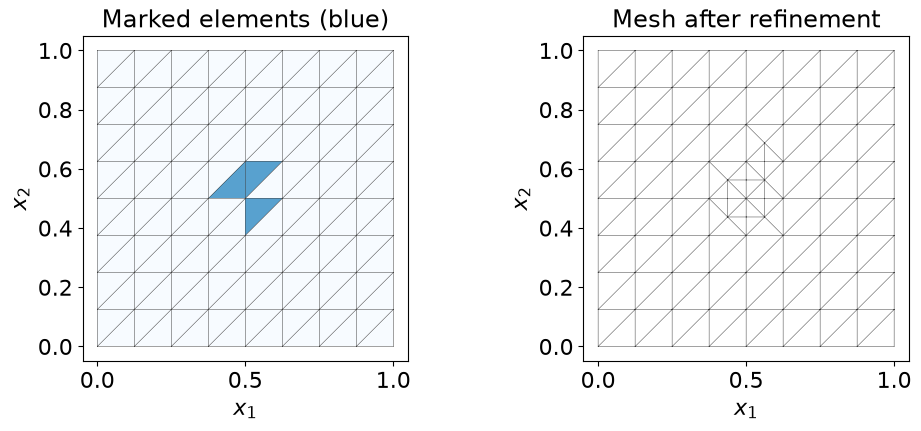

In [8]:
def refine_marked_elements(domain, marked):
    domain.topology.create_connectivity(2, 1)
    edges = mesh.compute_incident_entities(domain.topology, marked, 2, 1)
    refined_domain, _, _ = mesh.refine(domain, edges)
    return refined_domain

refined_domain = refine_marked_elements(domain, marked)
show_refinement(domain, refined_domain, marked)
plt.show()


Energy error: 1.323294 -> 0.760523
Estimator:    12.843903 -> 6.962192


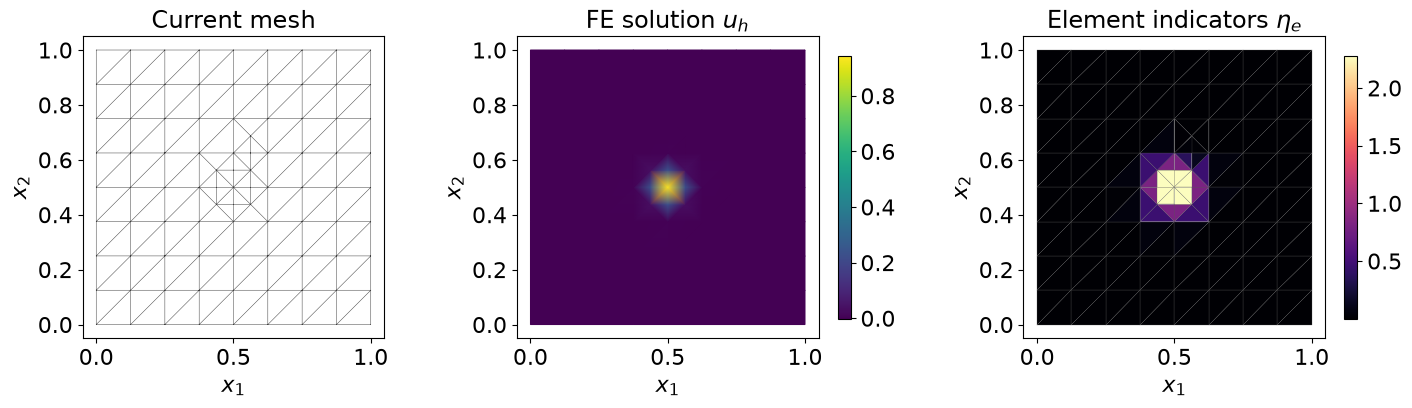

In [9]:
u_exact_new, f_new = pulse_data(refined_domain)
V_new, u_h_new = solve_diffusion(refined_domain, f_new)
element_new, facet_new = estimate_error(refined_domain, u_h_new, f_new)
eta_squared_new = element_new + facet_new
eta_new = np.sqrt(np.sum(eta_squared_new))
error_new = energy_error(refined_domain, u_h_new, u_exact_new)

print(f"Energy error: {error:.6f} -> {error_new:.6f}")
print(f"Estimator:    {eta:.6f} -> {eta_new:.6f}")
show_state(refined_domain, V_new, u_h_new, eta_squared_new)
plt.show()


## Additional supplied functions

The known solution permits an elementwise error calculation:
$$
E_e^2=\int_{\mathcal K_e}
\nabla(u_{\mathrm{ex}}-u_h)\cdot\nabla(u_{\mathrm{ex}}-u_h)\,d\boldsymbol x,
\qquad E_a^2=\sum_e E_e^2.
$$
`element_energy_errors` returns these **squared** errors in element order. This function is for verification; the adaptive algorithm must still mark using $\eta_e^2$.

`show_gaussian_selection` displays the indicators, selected elements, and actual refined mesh. A uniform-refinement calculation is also supplied for comparison.


In [10]:
def element_energy_errors(domain, u_h, u_exact):
    W = fem.functionspace(domain, ("DG", 0))
    z = ufl.TestFunction(W)
    error = u_exact - u_h
    dx = ufl.Measure("dx", domain=domain,
                     metadata={"quadrature_degree": quadrature_degree})
    vector = fem.assemble_vector(fem.form(
        ufl.dot(ufl.grad(error), ufl.grad(error))*z*dx))
    count = domain.topology.index_map(2).size_local
    squared_error = np.zeros(count)
    for e in range(count):
        squared_error[e] = vector.array[W.dofmap.cell_dofs(e)[0]].real
    return squared_error

def show_gaussian_selection(domain, eta_squared, marked, refined, title):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), layout="constrained")
    image = axes[0].tripcolor(mesh_triangles(domain), facecolors=np.sqrt(eta_squared),
                              cmap="magma", shading="flat")
    axes[0].triplot(mesh_triangles(domain), color="0.3", linewidth=0.3)
    axes[0].set(title=r"Indicators $\eta_e$", xlabel=r"$x_1$", ylabel=r"$x_2$",
                aspect="equal")
    fig.colorbar(image, ax=axes[0], shrink=0.8)
    draw_mesh(axes[1], domain, "Marked elements (blue)", marked)
    draw_mesh(axes[2], refined, "Mesh after refinement")
    fig.suptitle(title, fontsize=17)
    return fig


In [11]:
uniform_domain = create_square_mesh()
uniform_dofs, uniform_error = [], []
for level in range(5):
    exact_uniform, f_uniform = pulse_data(uniform_domain)
    V_uniform, u_uniform = solve_diffusion(uniform_domain, f_uniform)
    uniform_dofs.append(V_uniform.dofmap.index_map.size_global)
    uniform_error.append(energy_error(uniform_domain, u_uniform, exact_uniform))
    if level < 4:
        uniform_domain, _, _ = mesh.refine(uniform_domain)
display(pd.DataFrame({"total DOFs": uniform_dofs, "true energy error": uniform_error}))


,total DOFs,true energy error
0,81,1.323294
1,289,0.760451
2,1089,0.620598
3,4225,0.329934
4,16641,0.166056


## Task 1. Compare indicator-based and error-based selection (20 marks)

Use a **new initial mesh**, before any refinement, and set $\theta=0.5$.

1. Compute $\eta_e^2$ by adding the two arrays returned by `estimate_error`, and compute $E_e^2$ with `element_energy_errors`. Print $\eta=(\sum_e\eta_e^2)^{1/2}$ and $E_a=(\sum_eE_e^2)^{1/2}$. Check the latter against `energy_error(domain, u_h, u_exact)`.
2. Use `mark_elements` twice: first with $\eta_e^2$ to obtain $\mathcal M_\eta$, and then with $E_e^2$ to obtain $\mathcal M_E$. In a two-panel figure, show the initial mesh with $\mathcal M_\eta$ highlighted on the left and $\mathcal M_E$ on the right. Use the supplied `draw_mesh` function.
3. Print the number of elements in each set, the number selected by both, and the fraction of the **true squared energy error** covered by the residual-based set:
   $$
   \frac{\sum_{\mathcal K_e\in\mathcal M_\eta}E_e^2}{\sum_e E_e^2}.
   $$
   Does selecting at least half of $\eta^2$ select at least half of the true squared error in this calculation? Explain why the marking condition alone does not guarantee a true squared-error fraction of at least $1/2$ for every problem.

The error-based set is available only because the exact solution is known. It is not the marking rule to use in Task 2. Python element IDs start at zero.


In [12]:
# Compute the two selections and their covered error fractions here.


## Task 2. Write the adaptive loop and show its decisions (25 marks)

Start again from a new initial mesh and use $\theta=0.5$. Write a loop for **nine solves**, numbered 0 through 8. At each solve:

1. Rebuild the exact solution and source on the current mesh using `pulse_data`, solve, and compute $\eta_e^2$ and $E_a$.
2. Record the cycle, total scalar degrees of freedom, $E_a$, $\eta$, and $\eta/E_a$.
3. Except after the final solve, mark from $\eta_e^2$, check
   $\sum_{\mathcal K_e\in\mathcal M}\eta_e^2\ge\theta\sum_e\eta_e^2$,
   and refine the marked elements. Do not mark by distance from the Gaussian center or by the exact error.

At cycles **0, 3, and 6**, call `show_gaussian_selection(current_mesh, eta_squared, marked, refined_mesh, title)` **before replacing the current mesh**. Submit these three figures and one history table.

Using these figures, identify where the estimator selects elements as refinement progresses. Do not infer the marked set from the refined mesh alone: conformity can subdivide additional unmarked elements.


In [13]:
# Write the repeated solve-estimate-mark-refine loop here.


## Task 3. Reach a specified error with different marking choices (15 marks)

Repeat your loop for $\theta=0.3$ and $0.7$, again with nine solves and a fresh initial mesh for each run. Keep all three histories.

1. Plot **true energy error versus total scalar degrees of freedom** for the three adaptive runs and the supplied uniform run, on the same log-log axes.
2. Set the target $E_a\le0.25$. For each adaptive run, report the first cycle that reaches the target, its degree-of-freedom count, and its actual error. State explicitly if a run does not reach the target.
3. Among the meshes actually computed, which marking choice reaches the target with the fewest degrees of freedom? Use the table to justify the answer. Explain in one sentence why equal cycle numbers would not be a fair cost comparison.

No assumption that $\eta=E_a$ is permitted; the target in this task uses the known true error.


In [14]:
# Add the marking comparison, target table, and plot here.
